# Undertow DeepSea & False Beacon Frozen Lake
### Why more exploration can buy the wrong evidence

**Read the maps first.** A route can reach a dock, collect observations, and still fail to reveal that another route is better. These benchmarks separate **reward**, **coverage**, and **decision-relevant evidence**.

This walkthrough contains kernel-generated route illustrations, exact finite-model checks, and verified cached learning curves. Its default execution launches **no training**, downloads nothing, and needs no raw study folder.

**Setup must happen before launching the kernel.** From the repository root, in a terminal:

```bash
python3 -m venv .venv
source .venv/bin/activate
python -m pip install -e '.[notebook]'
python -m ipykernel install --sys-prefix --name ceac-undertow --display-name "Python (CEAC)"
python -m jupyter lab notebooks/Undertow_FalseBeacon.ipynb
```

Choose **Python (CEAC)**. In VS Code, select this repository's `.venv/bin/python`. Python 3.10 or newer is required; `ipykernel` is included in the notebook extra. Do not use the archived `legacy/inforatio` installer.

The saved outputs are also readable directly on GitHub.

In [1]:
from pathlib import Path
import sys, importlib.util

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "pyproject.toml").is_file() and (p / "ceac/model.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook inside the cloned CEAC repository.")
if sys.version_info < (3, 10):
    raise RuntimeError("Select the CEAC kernel with Python 3.10 or newer.")
missing = [name for name in ("numpy", "scipy", "matplotlib", "IPython", "ceac", "ceac_walkthrough")
           if importlib.util.find_spec(name) is None]
if missing:
    raise RuntimeError(f"Missing {missing}. In this kernel's environment run: "
                       f"{sys.executable} -m pip install -e '{ROOT}[notebook]'")
import numpy as np
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from ceac.model import FiniteModel
from ceac_walkthrough.evidence import verified_bundle
from ceac_walkthrough.visuals import (draw_undertow, draw_false_beacon, draw_signal_laws,
                                     draw_policy_facts)

bundle, provenance = verified_bundle(ROOT / "notebooks")
print(f"Python {sys.version.split()[0]} | verified {provenance['source_runs']} unique source runs")
print(f"Portable export: {provenance['curve_runs']} per-seed learning traces; no raw-cache dependency.")
from ceac.pathology_report import (strength_groups, draw_method_overlay,
                                   draw_strength_learning, draw_strength_diagnostics)
groups = strength_groups(bundle["curves"])
MODE = 1  # Set to 0 for the stationary normal-mode control; no retraining.
print("Matched physical-strength preflight:", bundle["strength_checks"])


Python 3.11.13 | verified 336 unique source runs
Portable export: 336 per-seed learning traces; no raw-cache dependency.
Matched physical-strength preflight: [{'context': 0, 'environment': 'deepsea', 'fixed_domain': True, 'fixed_optimum': True, 'fixed_return_range': True, 'fixed_useful_route_values_and_KL': True, 'strengths': [0.05, 0.25, 0.5, 0.75]}, {'context': 0, 'environment': 'frozenlake', 'fixed_domain': True, 'fixed_optimum': True, 'fixed_return_range': True, 'fixed_useful_route_values_and_KL': True, 'strengths': [0.05, 0.25, 0.5, 0.75]}]


## 1. Undertow: the horizon is a navigation budget

**Blue reaches the goal. Magenta generates observations while losing the ability to reach it.** Every rightward move spends one depth unit and gains one column. The nuisance action spends depth without gaining a column. Its random symbols have the same law in both candidate modes.

The gate offers a different choice: a small-cost probe reveals a mode-sensitive bit. A challenge follows the ordinary route geometry but has a mode-dependent payoff. The map below is generated by actual `reset`/`step` calls; it is an illustrative trajectory, not a trained-policy success statistic.

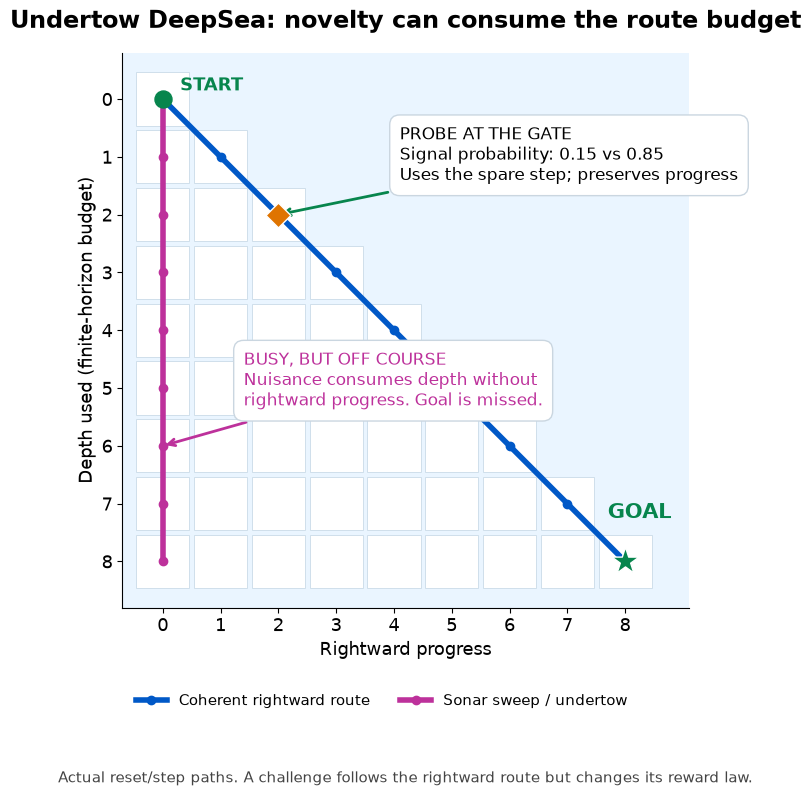

In [2]:
fig = draw_undertow()
plt.show()

## 2. False Beacon: a successful route can leave the decision unresolved

**The inner route has the same trajectory law in both modes; the outer route becomes better in mode 1.** Repeating the inner route therefore cannot detect this opportunity.

The noisy reeds are a false beacon: they offer more observable variety without revealing the mode. The deep survey supplies useful evidence. The shallow survey is also uninformative about the mode. Geometry and paths below come from the environment implementation. Random terminal outcomes mean reaching a dock and obtaining a reward are distinct events.

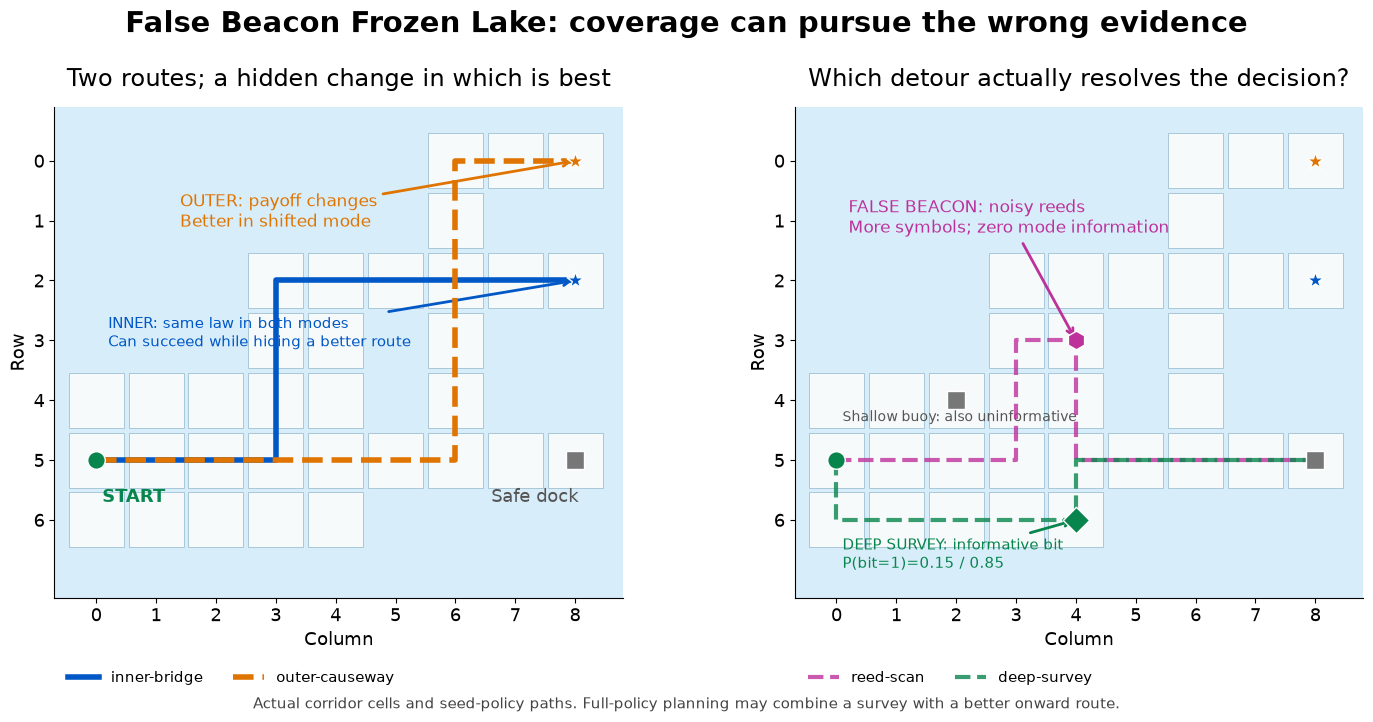

In [3]:
fig = draw_false_beacon()
plt.show()

## 3. What makes an observation useful?

The relevant quantity is a likelihood ratio against a **policy-changing** alternative, not the number of distinct symbols. If both modes emit a symbol with probability $1/M$, its log likelihood ratio is zero even though its entropy is $\log M$.

The two-outcome probe is much simpler, but separates Bernoulli(0.15) from Bernoulli(0.85):

$$D_{\mathrm{KL}} = 0.7\log(17/3) \simeq 1.214\ \text{nats}.$$

**A richer observation alphabet can be less useful for the decision.** These charts show declared observation laws, not sampled training histograms.

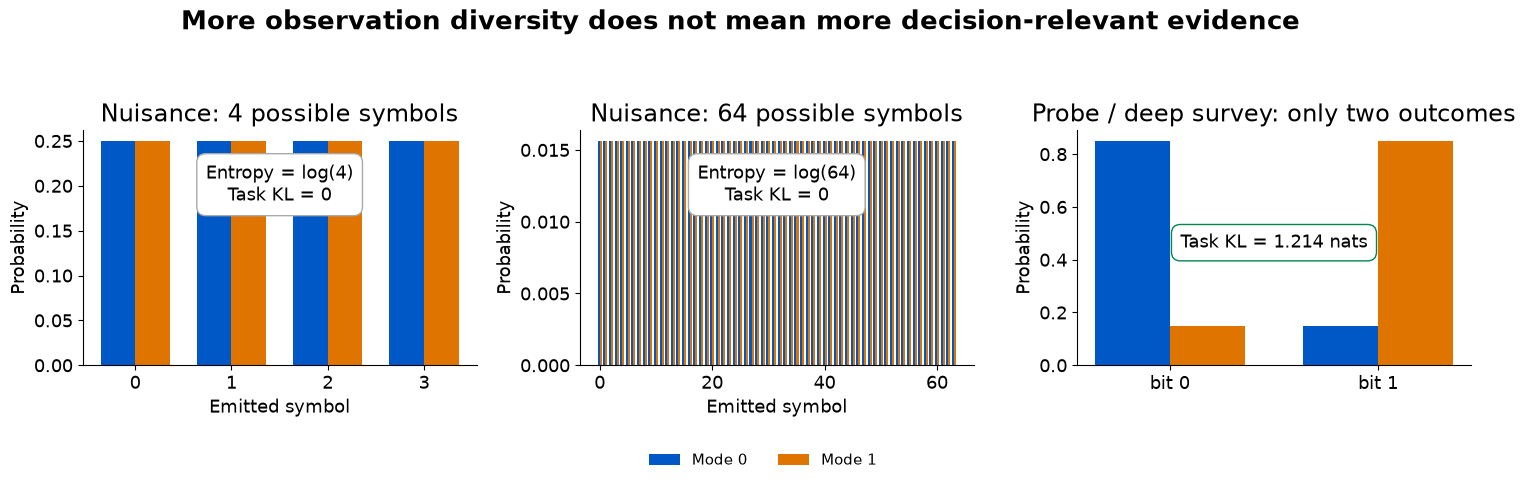

In [4]:
fig = draw_signal_laws()
plt.show()

## 4. Check the pathology against the actual finite models

We now compile both candidate laws from each environment's `step()` behavior at **weak signal, M=4**, and evaluate the seed policies exactly. This is diagnostic planning, not self-play training.

The assertions require: (i) the old route is observationally identical across modes, (ii) it becomes suboptimal in mode 1, (iii) the nuisance policy has zero task KL, and (iv) the probe/survey is informative. The frozen-lake survey shown is the declared seed route; full-policy separation can synthesize a better onward continuation.

Both environments pass the confounding, nuisance and informative-probe checks.


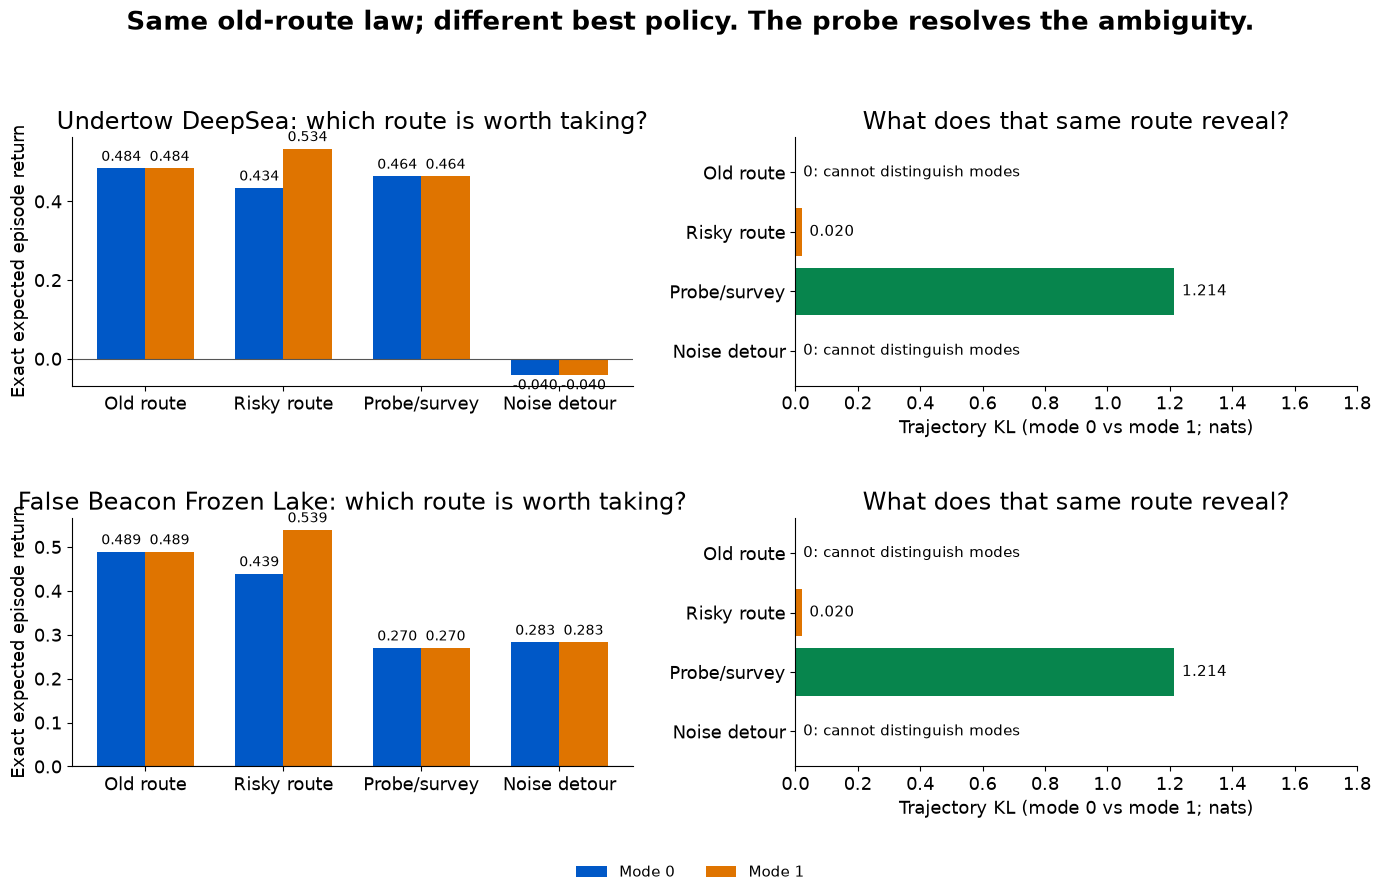

In [5]:
models = {kind: FiniteModel(kind, benchmark="weak_signal_m4")
          for kind in ("deepsea", "frozenlake")}
for kind, model in models.items():
    policies = {p.label: p for p in model.seed_policies()}
    old, noise, probe = (("exploit", "sonar-sweep", "probe") if kind == "deepsea"
                         else ("inner-bridge", "reed-scan", "deep-survey"))
    values, information = model.evaluate(policies[old])
    np.testing.assert_allclose(information, 0, atol=1e-12)
    np.testing.assert_allclose(values[0], values[1], atol=1e-12)
    assert model.optimal_returns[1] - values[1] > 0.049
    np.testing.assert_allclose(model.evaluate(policies[noise])[1], 0, atol=1e-12)
    assert model.evaluate(policies[probe])[1][0, 1] > 1.2
print("Both environments pass the confounding, nuisance and informative-probe checks.")
fig = draw_policy_facts(models)
plt.show()

## 5. Overlay optimism, frequentist IDAC and Bayesian IDS

The saved sweep has **four physical diversion probabilities**, two environments, two stationary modes, three seeds, and **2,048 training episodes per cell**. Each panel overlays the actual runs of:

- UCB-Hoeffding Q-learning (greedy actions).
- Optimistic POMD (softmax mirror descent).
- IDAC (frequentist cost/occupancy-entropy actor-critic).
- Full-support Bayesian IDS.
- CEAC (exact-model single loop) and the offline Graves–Lai oracle.

**IDAC and Bayesian IDS have different objectives.** IDAC optimizes a cost-to-occupancy-entropy ratio; Bayesian IDS uses posterior regret and information about the task model. They are not interchangeable versions of one estimator.

Color identifies the method and remains fixed across panels. The symlog regret axis shows both large exploration costs and small residual costs; the next figure uses a shared linear axis. Shading is **mean ±1 sample SD across seeds**, not a confidence interval. CEAC/IDS have candidate-model access; the primitive learners receive the public domain, reward bounds and observed transitions.

These are the same rendering functions called by the standard report command, not separate notebook plots.


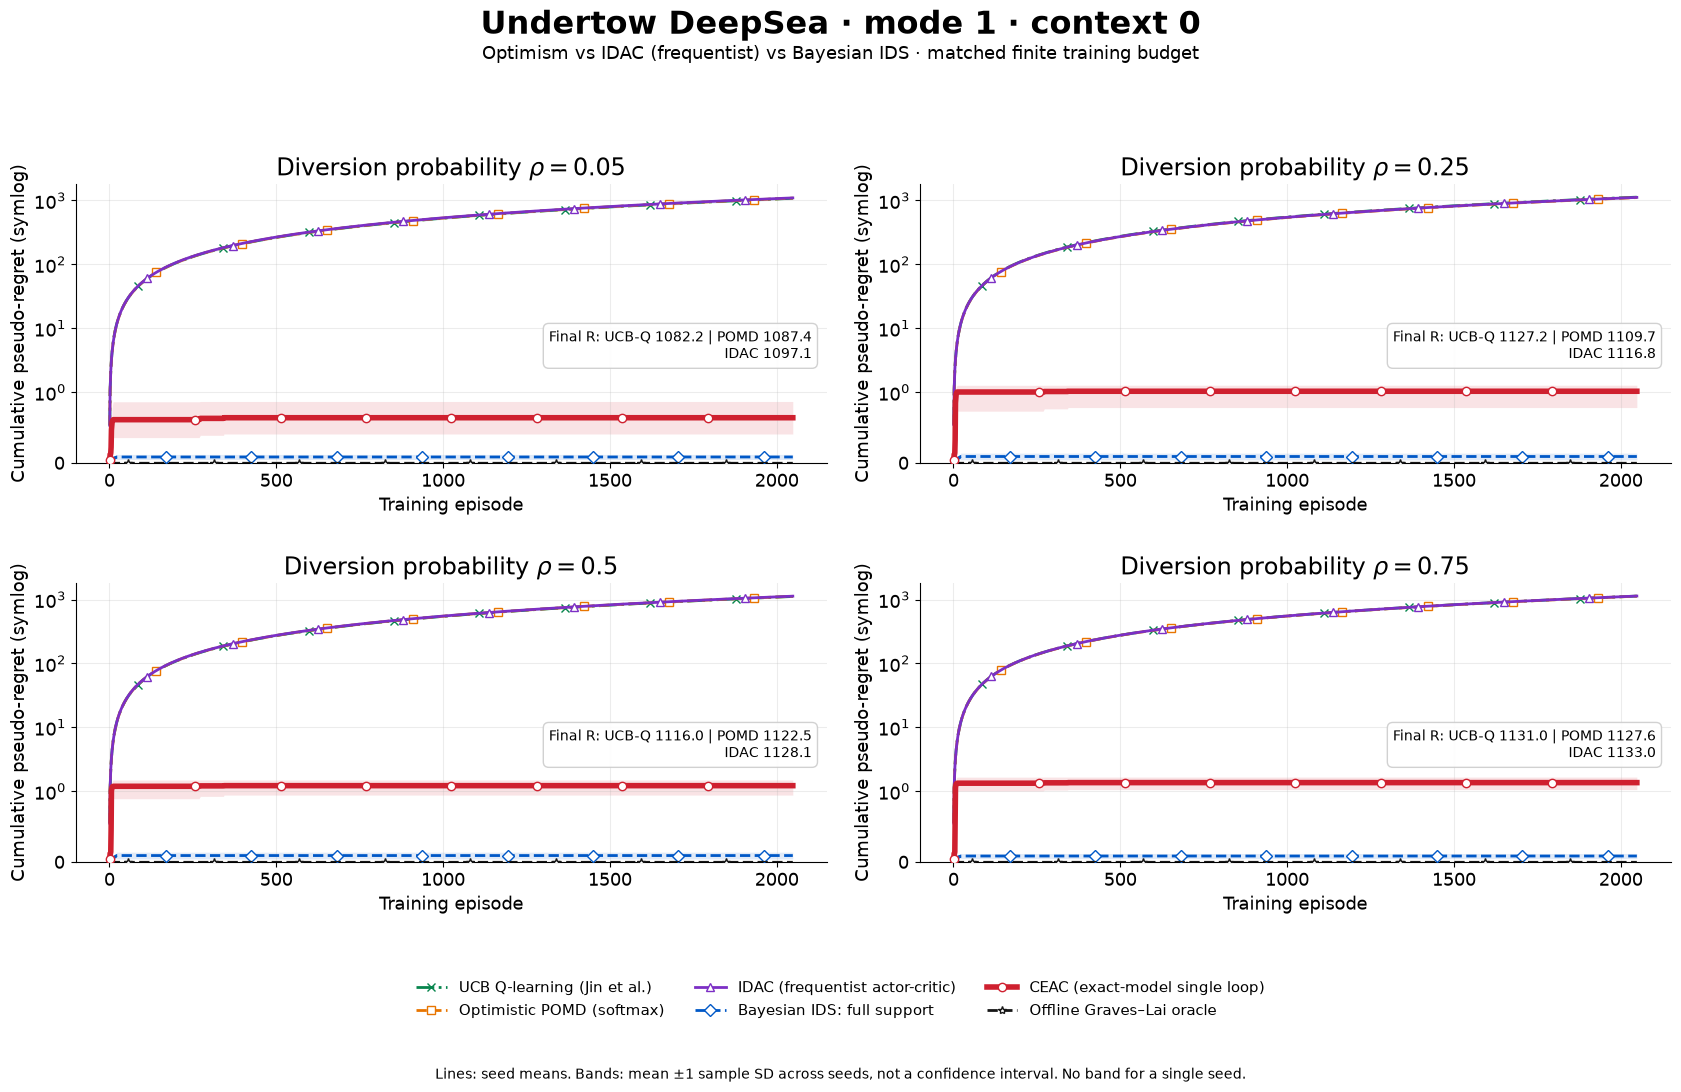

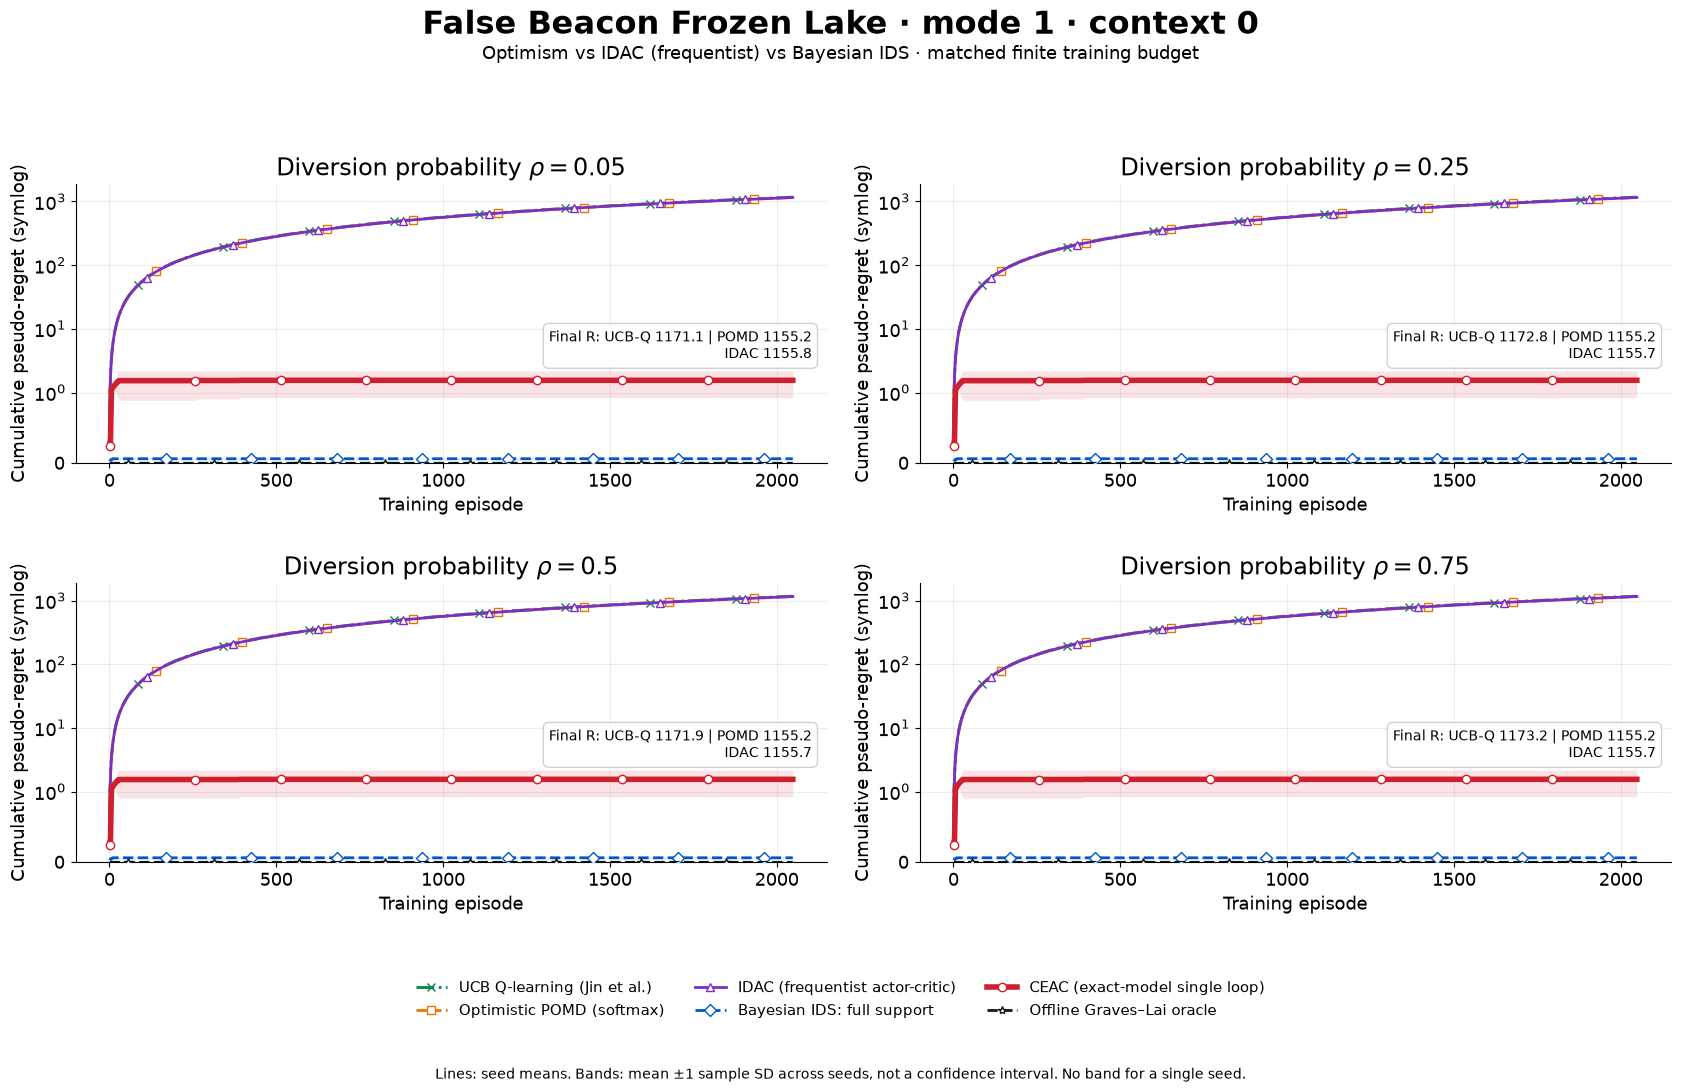

In [6]:
for kind in ("deepsea", "frozenlake"):
    fig = draw_method_overlay(groups, kind, mode=MODE)
    plt.show()


## 6. Increase physical pathology while keeping the task fixed

$$P_{m,\rho}(\cdot\mid s,a_N)
=(1-\rho)P_{\mathrm{pass}}(\cdot\mid s,a_N)+\rho P_{\mathrm{divert}}(\cdot\mid s,a_N).$$

The sweep uses $\rho=0.05,0.25,0.50,0.75$. Both branches are mode independent. Interior probabilities preserve an identical reachable state/action domain. Geometry, horizon, the four-symbol alphabet, optimal values, useful-route values, reward range and probe KL are checked across settings before training.

- **Undertow:** a nuisance move loses rightward progress with probability $\rho$; otherwise it advances.
- **False Beacon:** the first reed visit causes a forced dwell with probability $\rho$. It consumes one physical step. The observable state records pending/completed dwell, and the intended route resumes afterward.

The introductory route maps illustrate the geometry and deterministic nuisance behavior, not a sampled training curve. The new sweep changes physical diversion probability, **not symbol diversity**.

Following STEERING, each method now has a panel: **x = training episode, y = cumulative pseudo-regret, color = physical strength**. All panels share a linear y scale:

$$R_T=\sum_{t=1}^{T}\big[J_m^\star-J_m(\pi_t)\big].$$

The evaluator computes regret against the true-mode optimal value; the executed oracle allocation is not the reference. Coincident curves remain coincident. Stronger harm need not defeat a policy that learns to avoid it.

The additional-cost panels subtract the mildest-strength curve **within each seed before computing the SD**. Negative values mean lower measured regret than at mild strength; they are not clipped away.


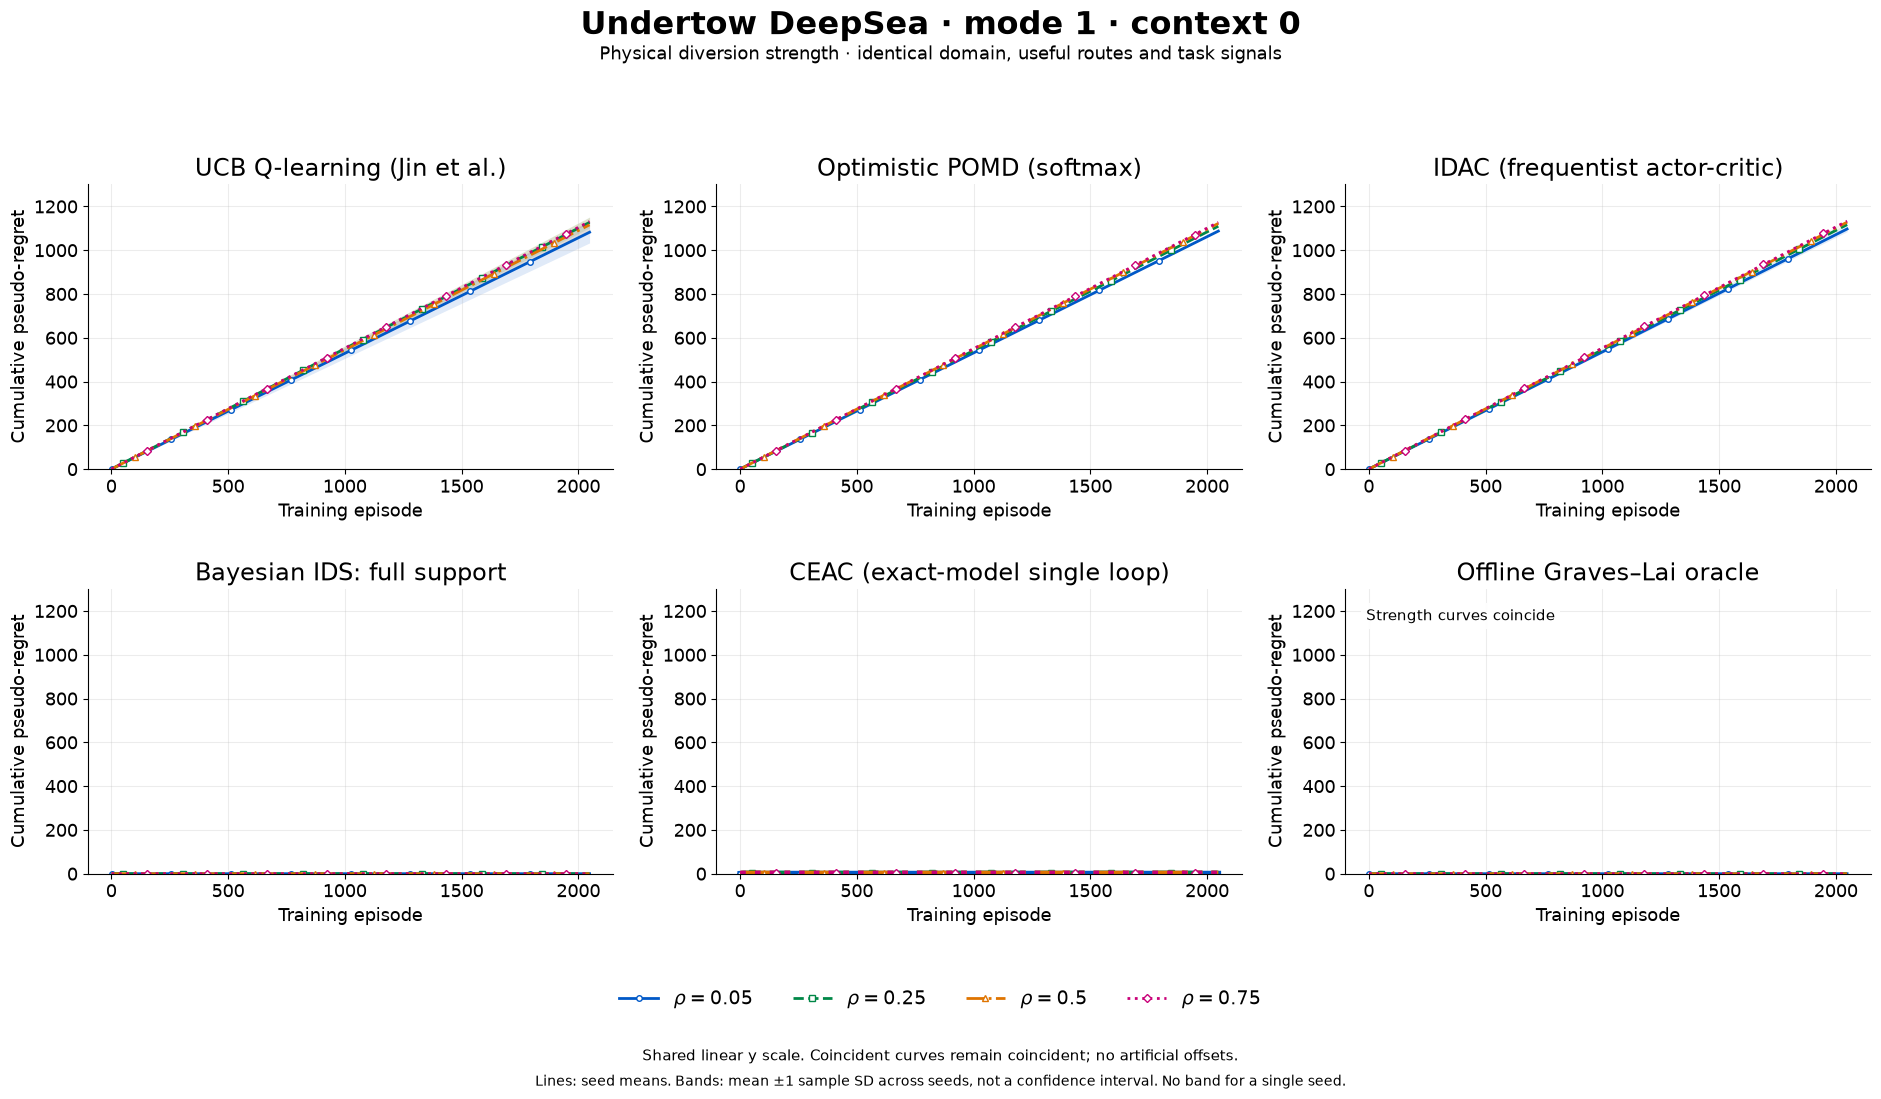

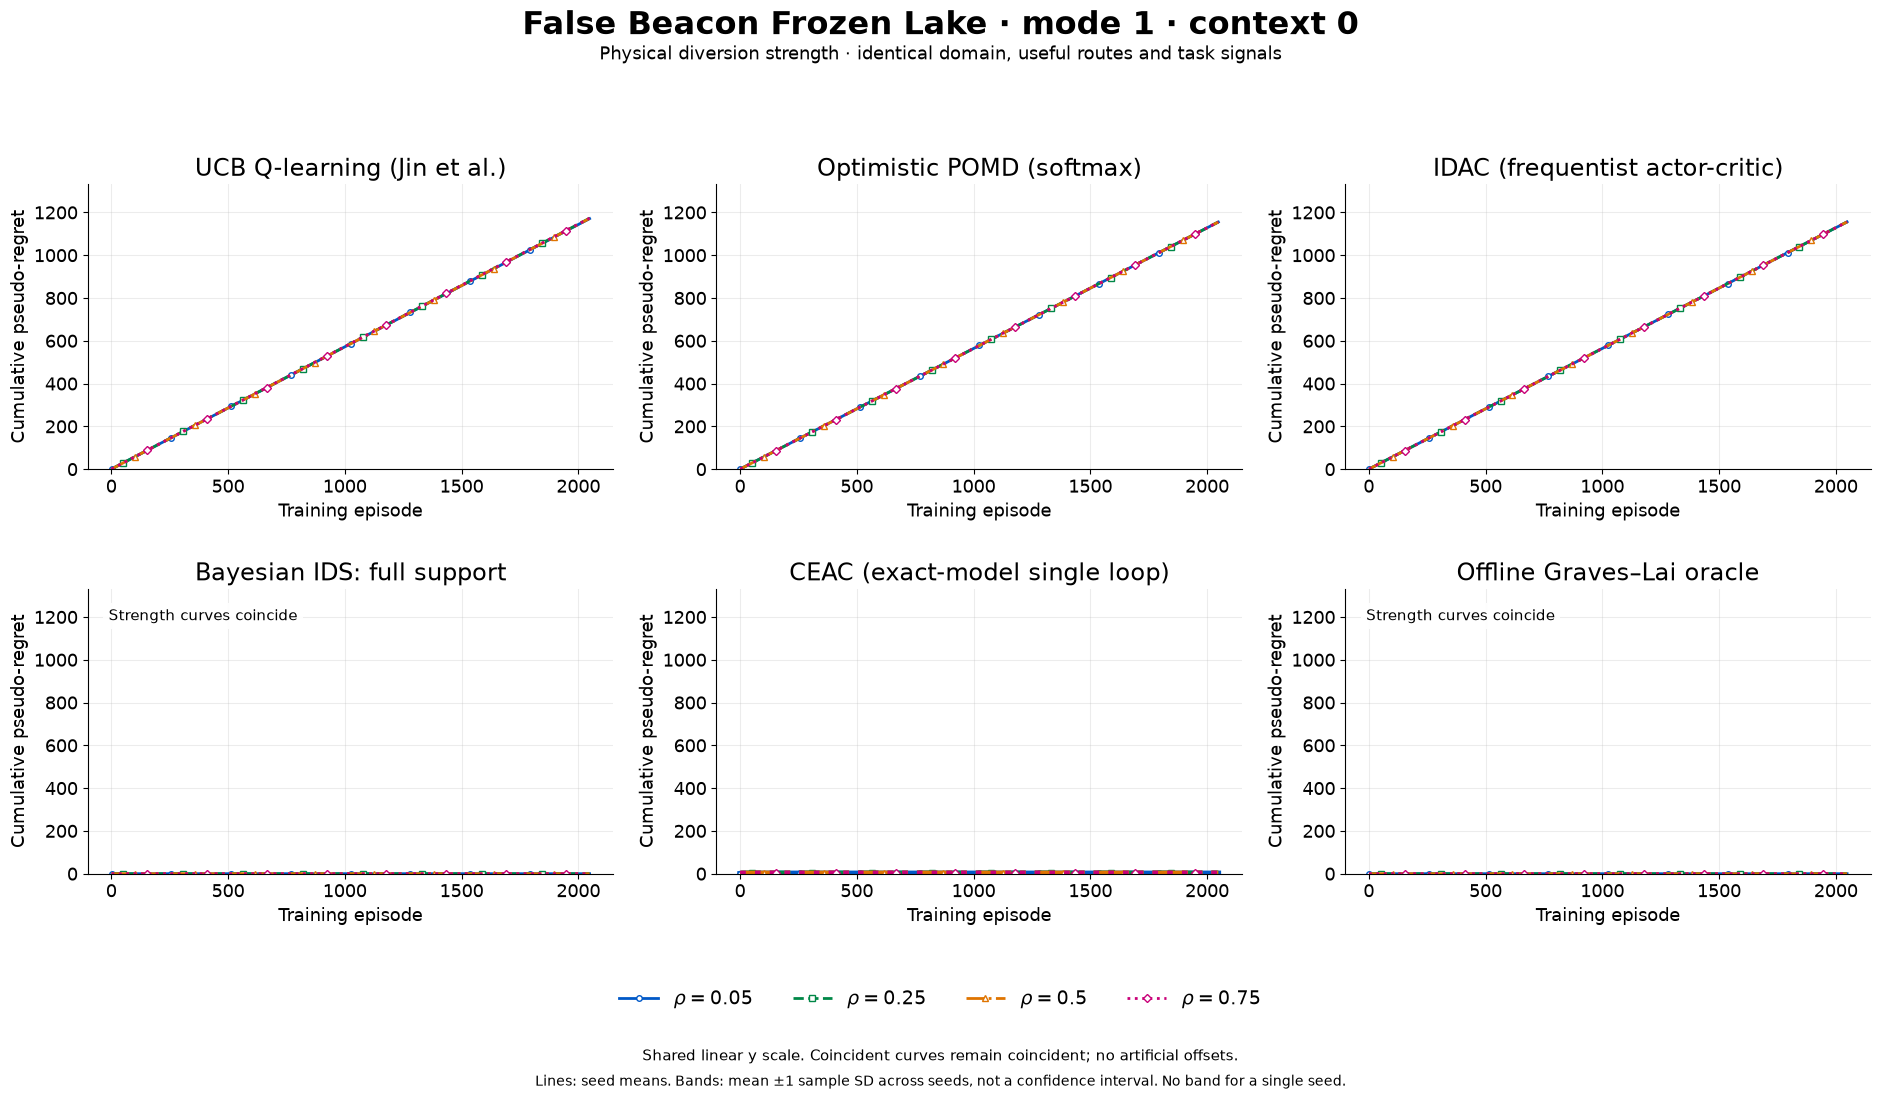

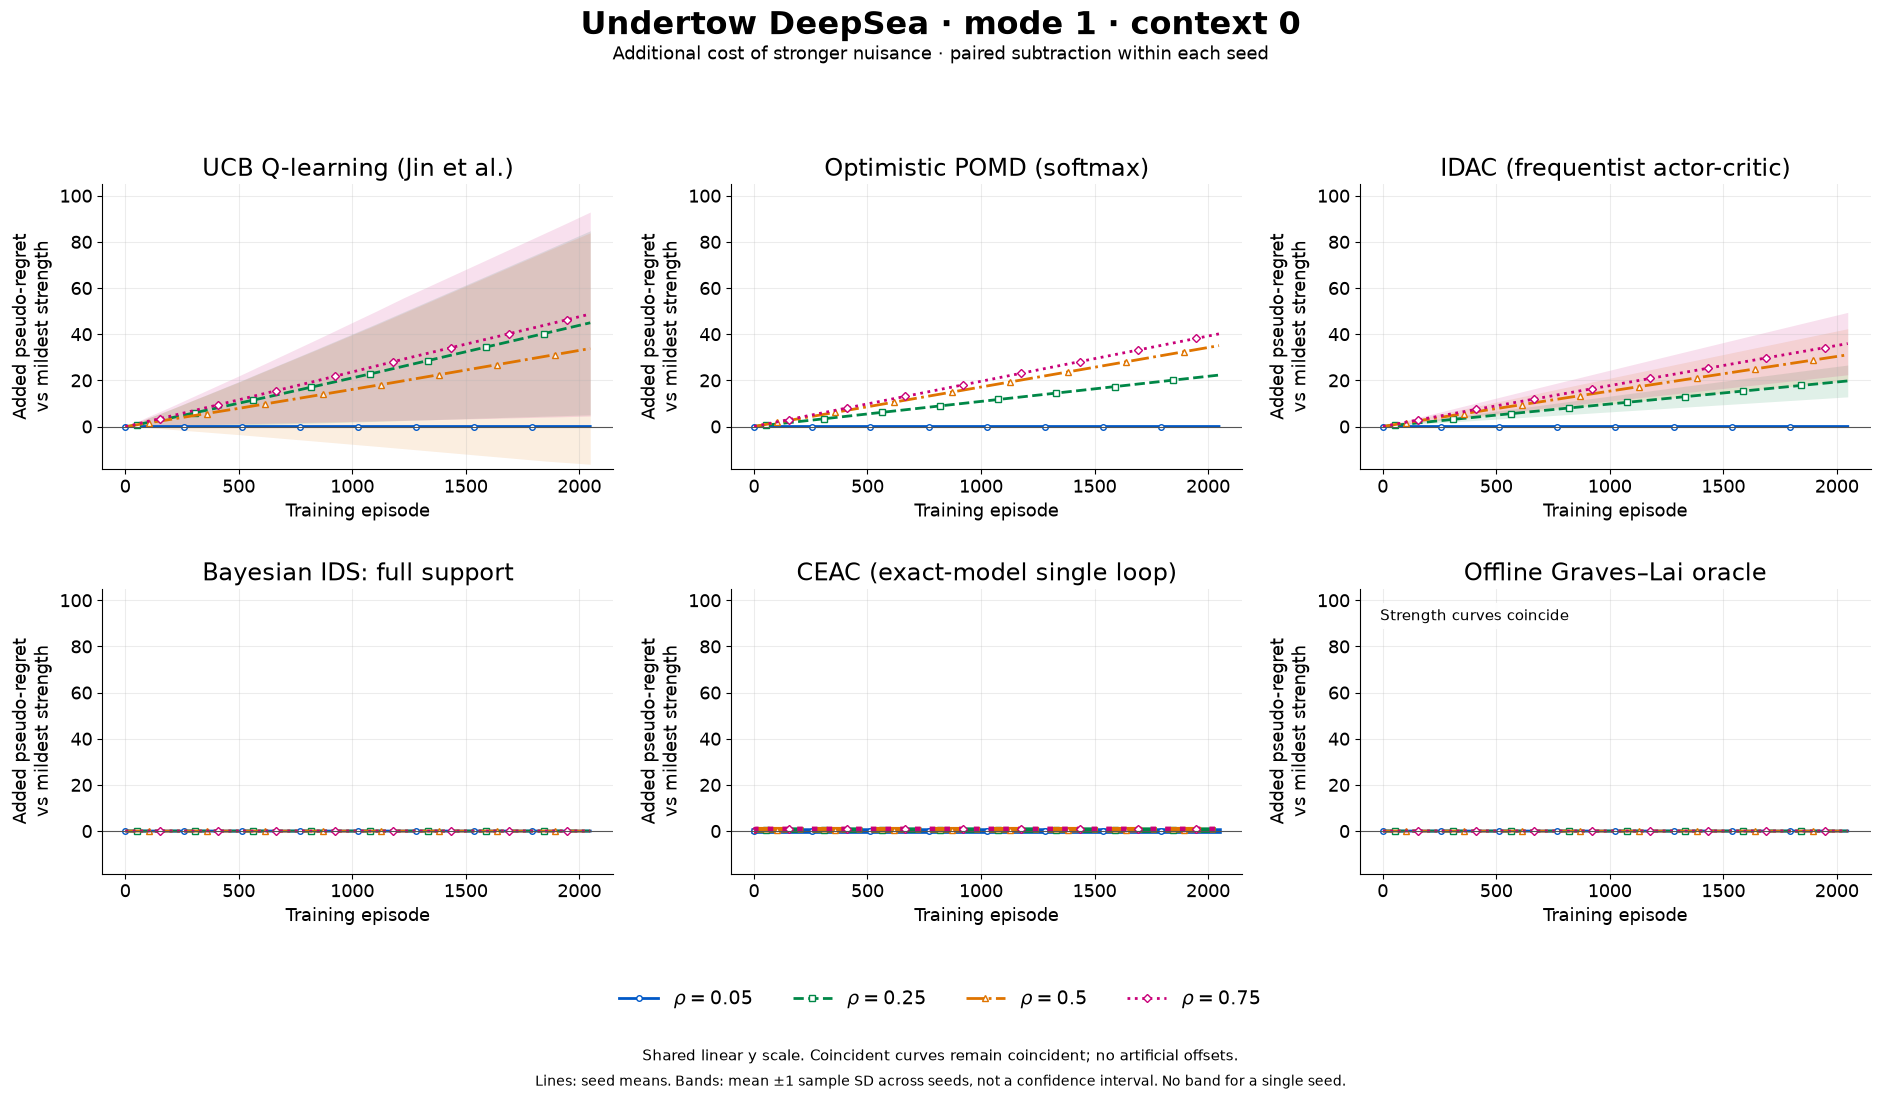

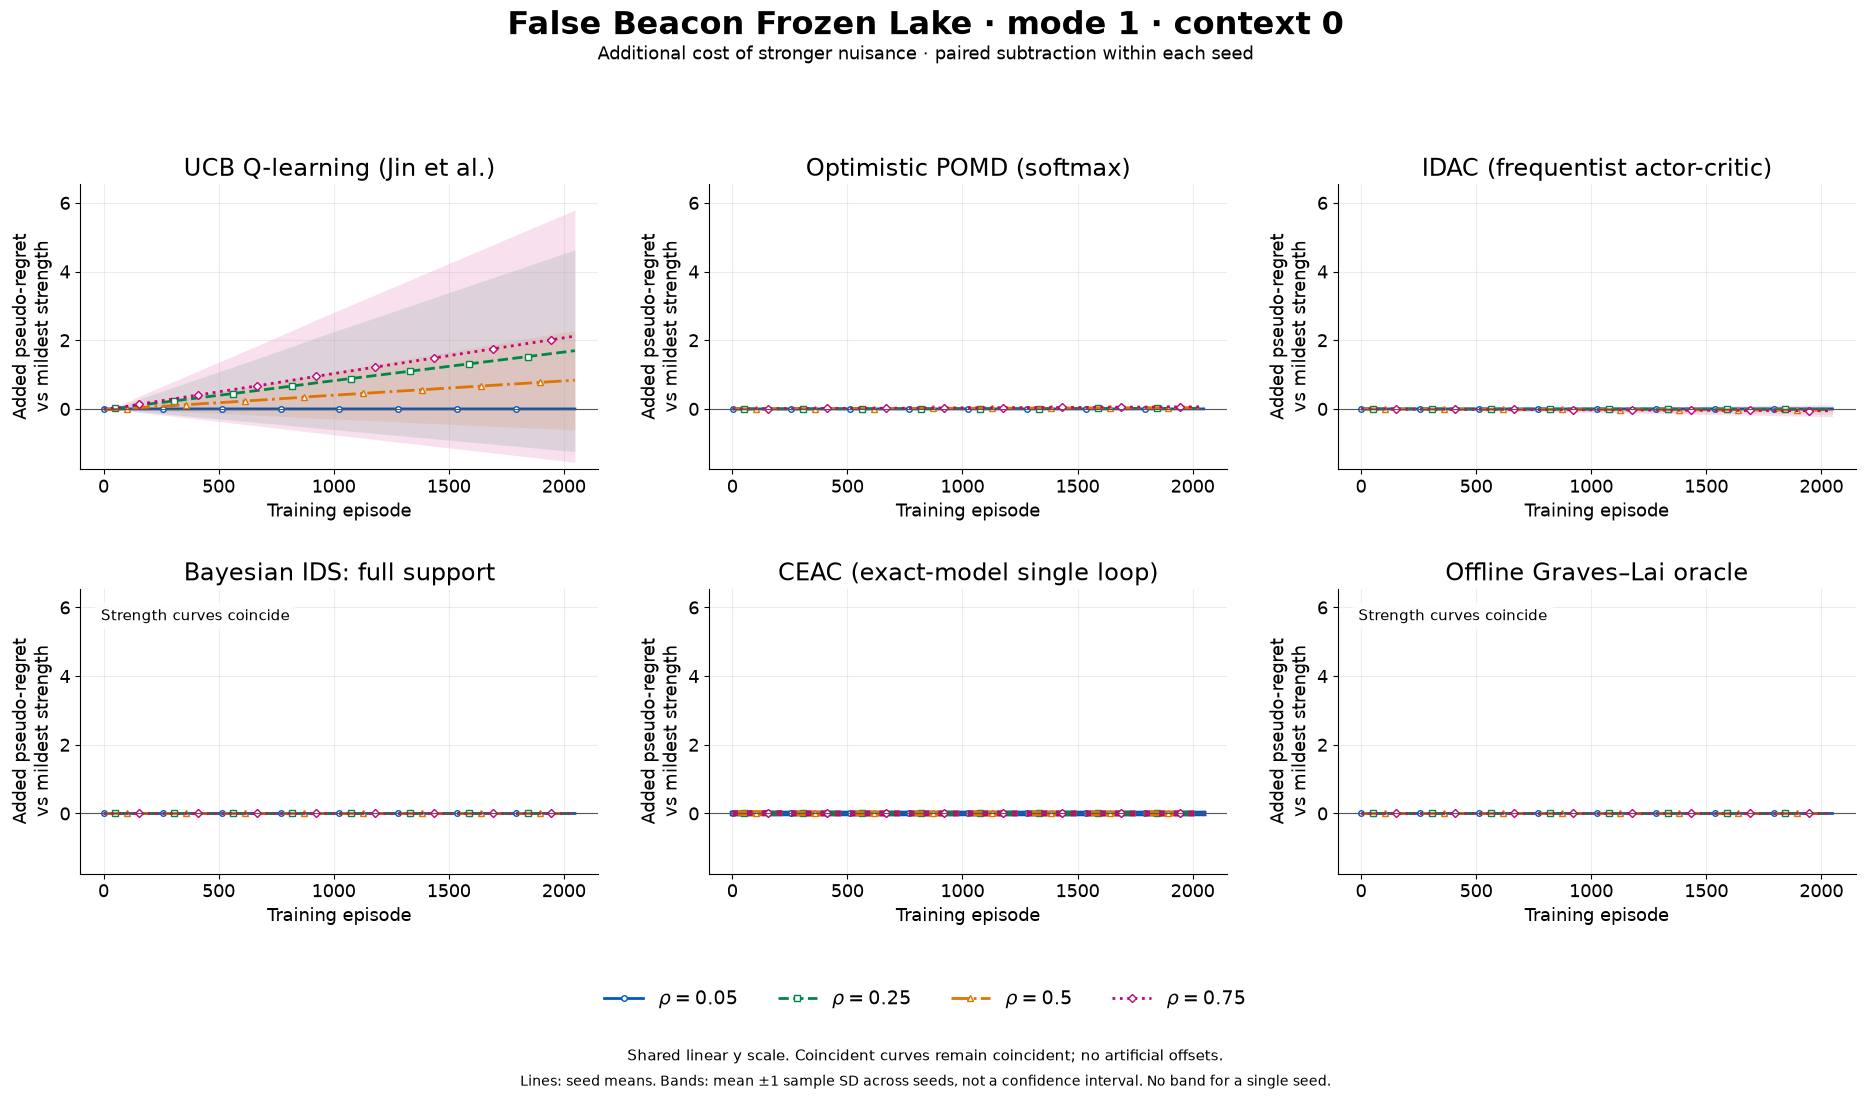

In [7]:
for kind in ("deepsea", "frozenlake"):
    fig = draw_strength_learning(groups, kind, mode=MODE)
    plt.show()

# Subtract the mildest-strength curve within each seed before computing SD.
for kind in ("deepsea", "frozenlake"):
    fig = draw_strength_learning(groups, kind, mode=MODE, incremental=True)
    plt.show()


### What actually went wrong?

The diagnostics distinguish failure to reach a rewarding terminal state, residual value gap, physical nuisance exposure, and lack of useful evidence. A plateau already present at mild strength cannot be attributed entirely to increasing pathology.

The flags are descriptive: POMD_BONUS_SATURATION means all optimistic costs were zero in at least 90% of episodes; PHYSICAL_NUISANCE_EXPOSURE records lost progress/dwell; FINITE_BUDGET_VALUE_GAP means the final 32-episode mean value gap exceeds 0.01. They are not causal ablations or asymptotic failure claims. Seed-level data and paired strong-minus-mild regret are exported automatically in pathology_statistics.json.


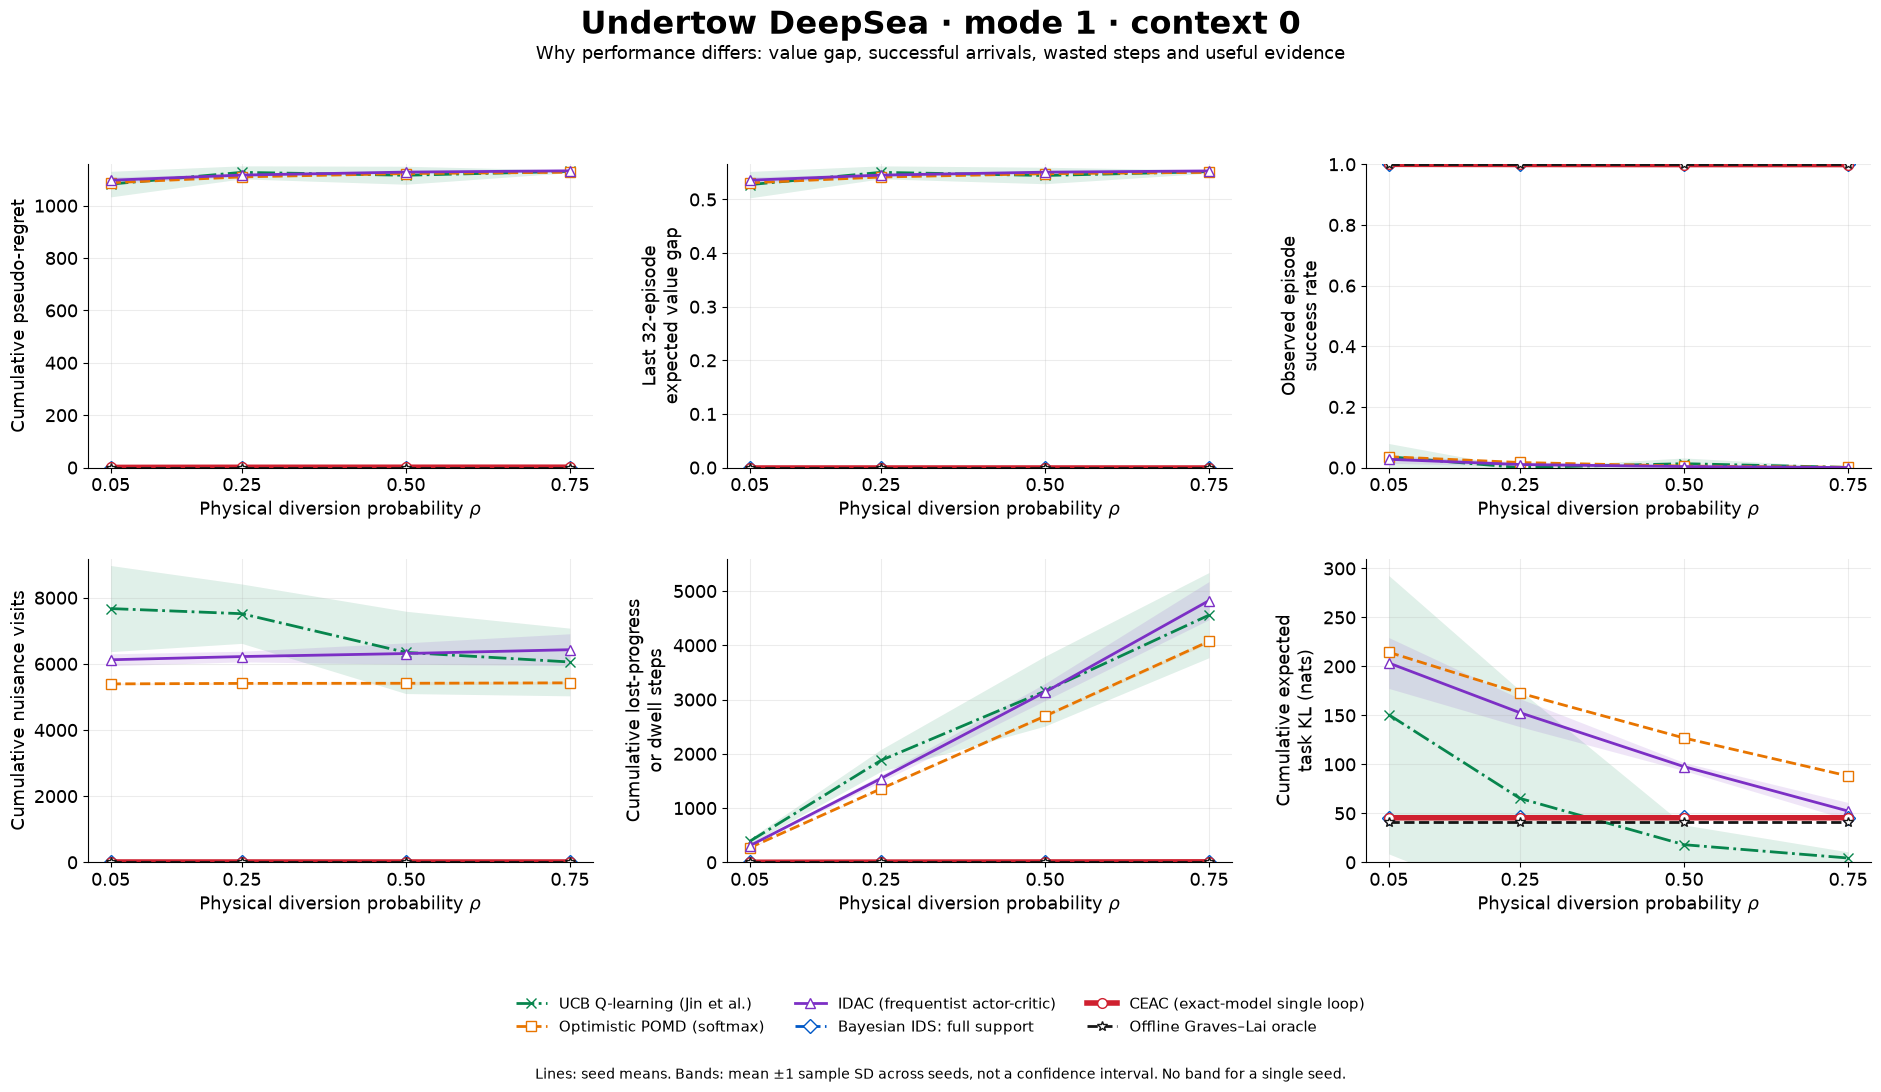

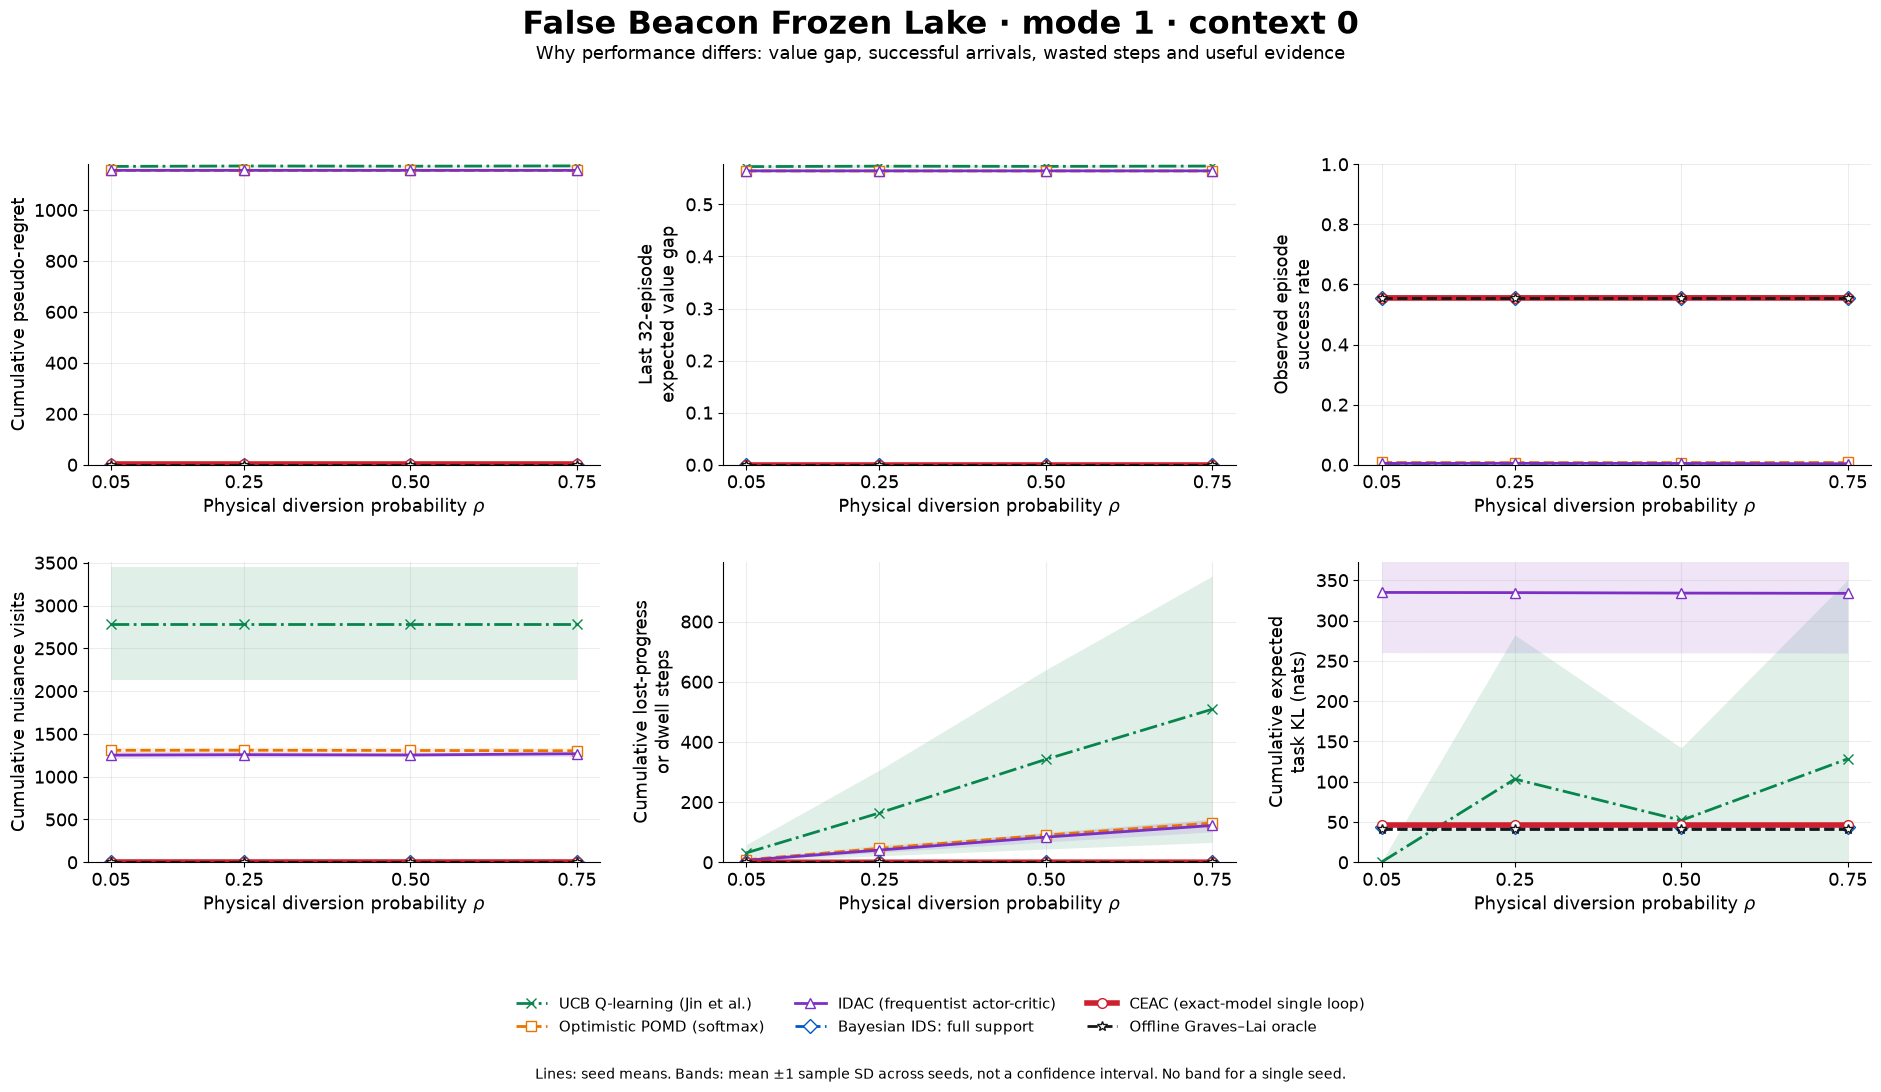

deepsea ucb_q strong-minus-mild regret: 48.740 ± 44.195 SD; ['FINITE_BUDGET_VALUE_GAP', 'PHYSICAL_NUISANCE_EXPOSURE']
frozenlake ucb_q strong-minus-mild regret: 2.120 ± 3.673 SD; ['FINITE_BUDGET_VALUE_GAP', 'PHYSICAL_NUISANCE_EXPOSURE']
deepsea pomd strong-minus-mild regret: 40.141 ± 0.000 SD; ['FINITE_BUDGET_VALUE_GAP', 'PHYSICAL_NUISANCE_EXPOSURE', 'POMD_BONUS_SATURATION']
frozenlake pomd strong-minus-mild regret: 0.062 ± 0.000 SD; ['FINITE_BUDGET_VALUE_GAP', 'PHYSICAL_NUISANCE_EXPOSURE', 'POMD_BONUS_SATURATION']
deepsea idac strong-minus-mild regret: 35.937 ± 13.519 SD; ['FINITE_BUDGET_VALUE_GAP', 'PHYSICAL_NUISANCE_EXPOSURE']
frozenlake idac strong-minus-mild regret: -0.054 ± 0.171 SD; ['FINITE_BUDGET_VALUE_GAP', 'PHYSICAL_NUISANCE_EXPOSURE']
deepsea ids strong-minus-mild regret: 0.000 ± 0.000 SD; ['no flagged gap']
frozenlake ids strong-minus-mild regret: 0.000 ± 0.000 SD; ['no flagged gap']
deepsea ceac strong-minus-mild regret: 0.724 ± 0.074 SD; ['PHYSICAL_NUISANCE_EXPOSURE']
fr

In [8]:
for kind in ("deepsea", "frozenlake"):
    fig = draw_strength_diagnostics(bundle["pathology_statistics"], kind, mode=MODE)
    plt.show()
for method in ("ucb_q", "pomd", "idac", "ids", "ceac"):
    rows = [r for r in bundle["pathology_statistics"]
            if r["mode"] == MODE and r["rho"] == .75 and r["method"] == method]
    for kind in ("deepsea", "frozenlake"):
        subset = [r for r in rows if r["environment"] == kind]
        delta = np.array([r["added_regret"] for r in subset])
        flags = sorted({f for r in subset for f in r["diagnostic_flags"]})
        print(kind, method, "strong-minus-mild regret:",
              f"{delta.mean():.3f} ± {delta.std(ddof=1):.3f} SD;", flags or ["no flagged gap"])


## 7. Bayesian support exclusion is a separate failure mechanism

Full-support Bayesian IDS is retained in the main overlays. The additional ids_zero arm deliberately assigns mode 1 zero prior probability:

$$p_t(1)=\frac{p_0(1)L_t(1)}{p_0(0)L_t(0)+p_0(1)L_t(1)}=0.$$

In mode 1 it never requests the diagnostic. The old route has true gap 0.05, giving exactly $2,048\times0.05=102.4$ cumulative pseudo-regret at every diversion strength. This is a failure of excluded prior support, not evidence that increasing physical nuisance defeats full-support Bayesian IDS. A small positive prior is a different treatment.

The following overlays explicitly separate these Bayesian assumptions. CEAC still has both candidate models, so they do not establish discovery outside its declared family.


Checked the exact zero-support prediction in all 24 shifted-mode runs.


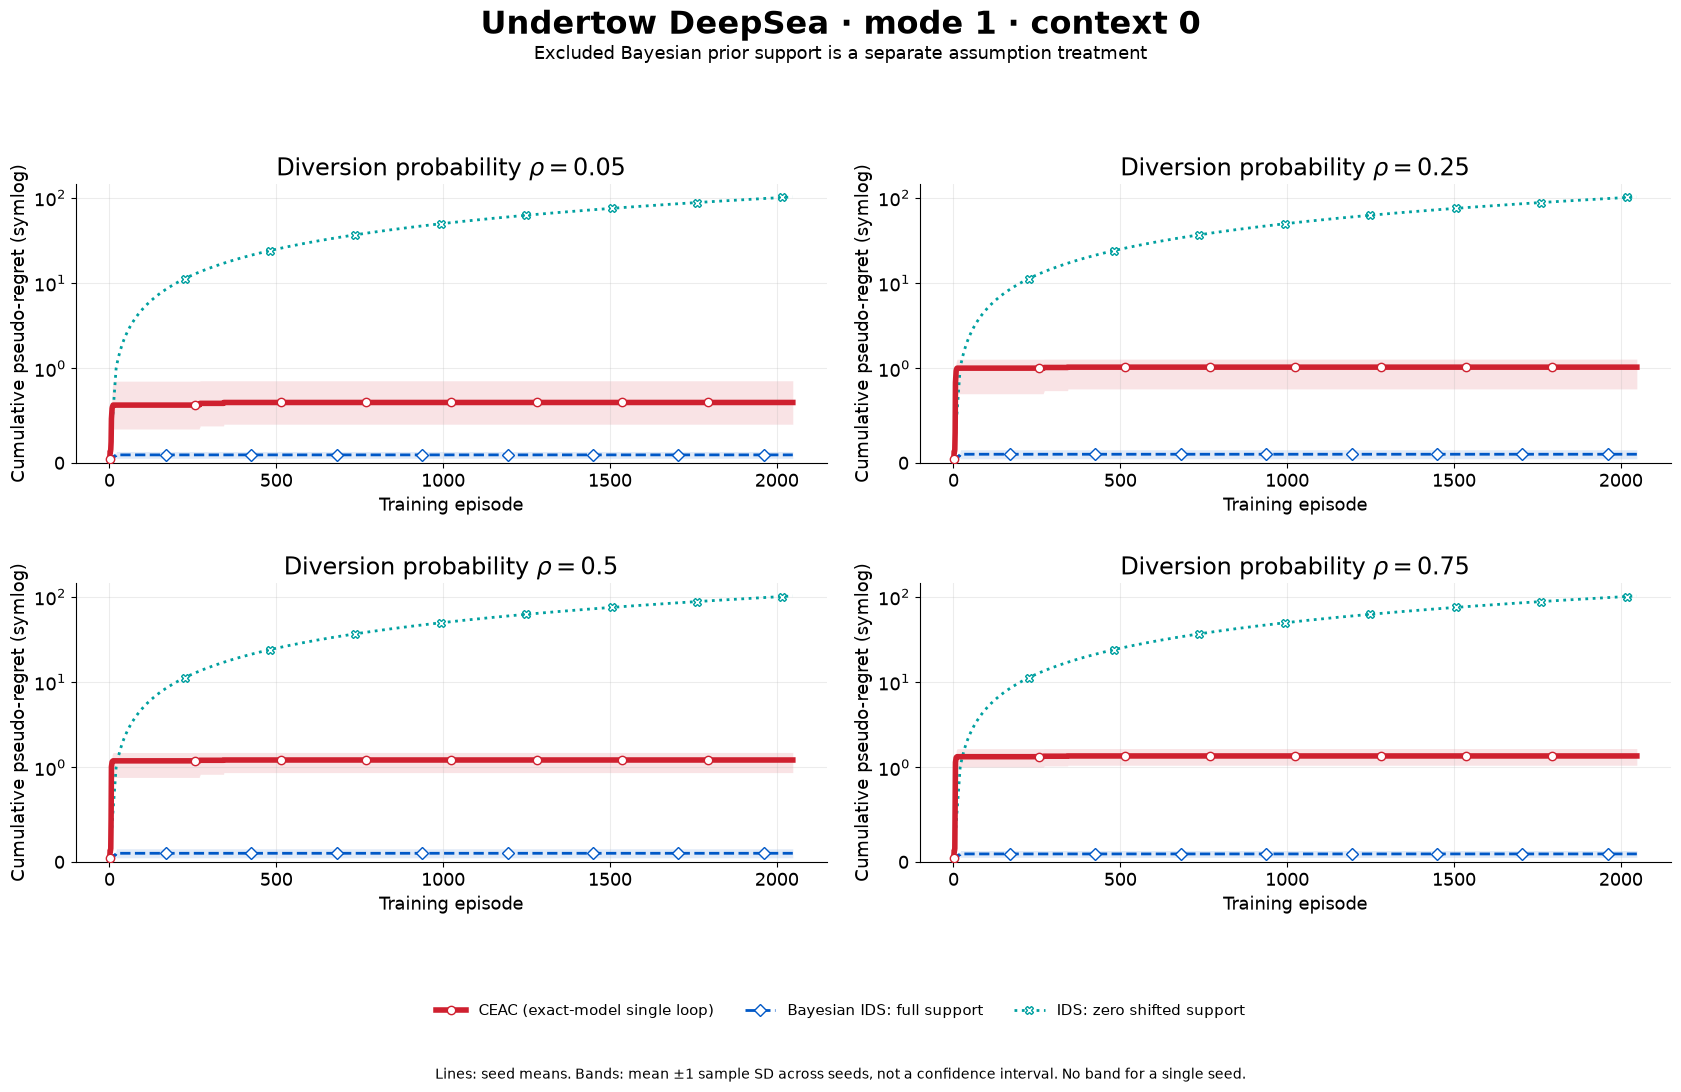

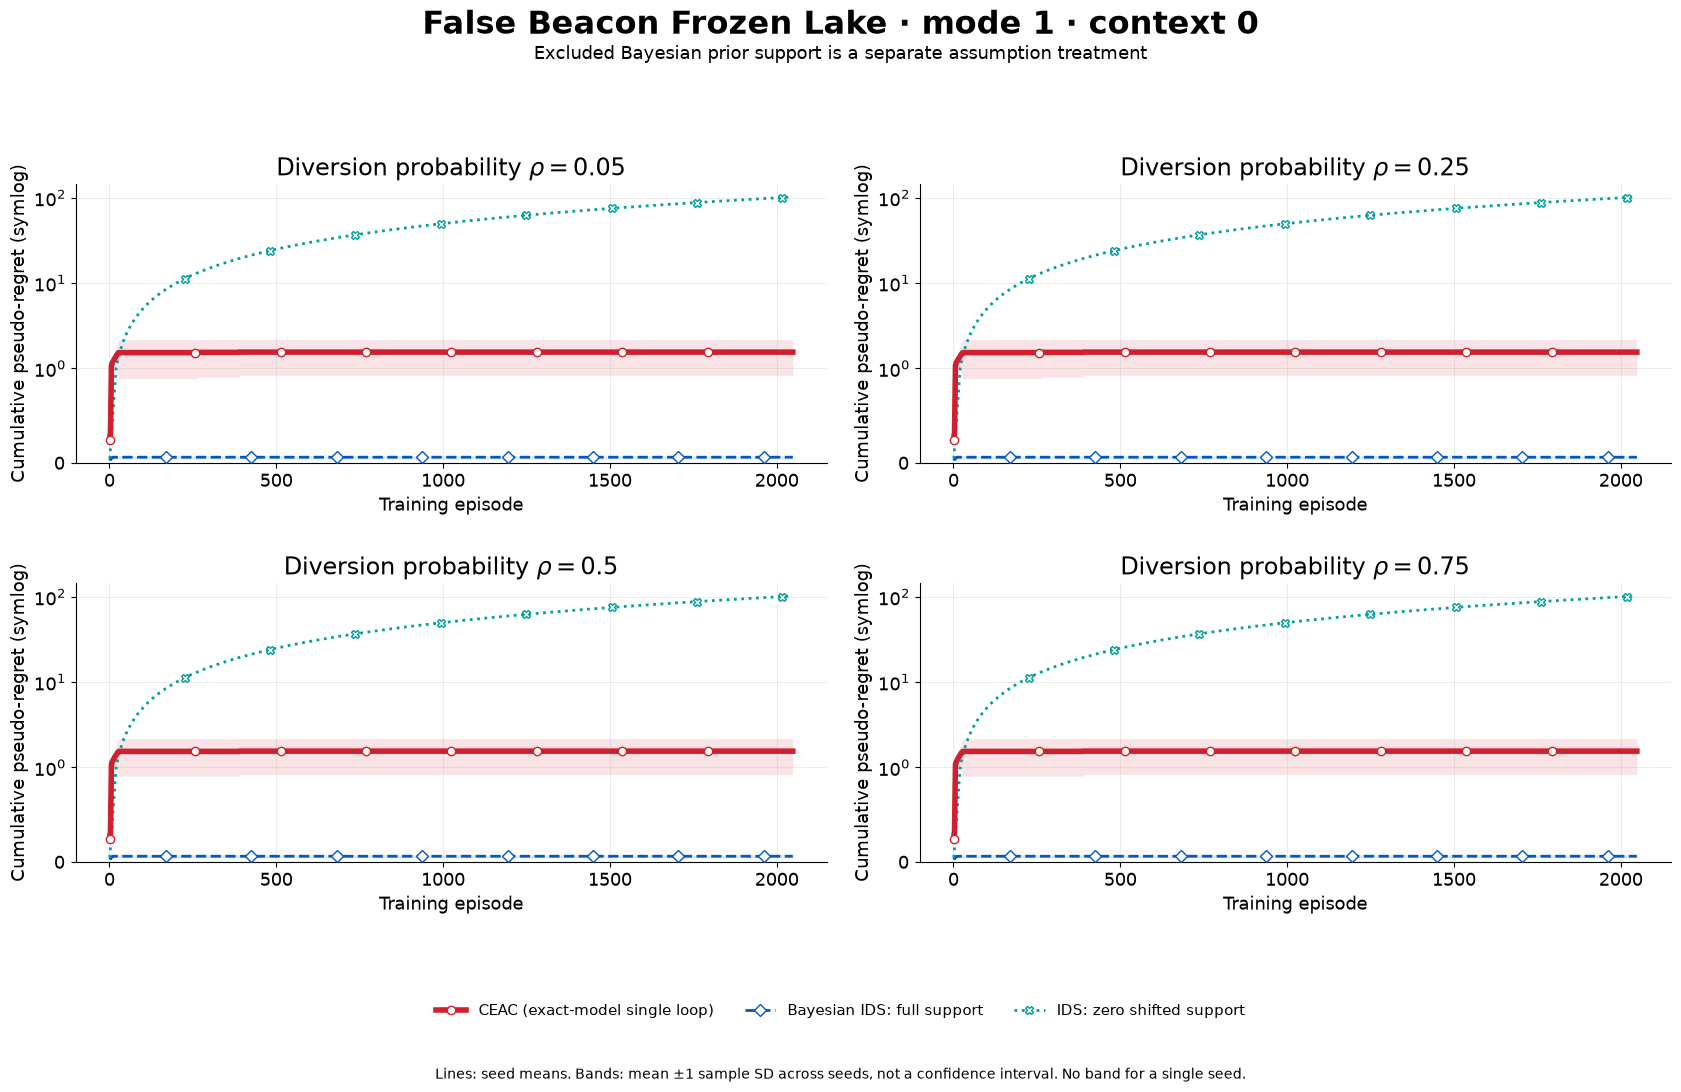

In [9]:
excluded = [r for r in bundle["curves"] if r["result"]["method"] == "ids_zero"
            and r["result"]["true_mode"] == 1]
assert excluded
for run in excluded:
    posterior = [m["diagnostics"]["posterior"][1] for m in run["metrics"]]
    np.testing.assert_array_equal(posterior, 0)
    T = run["result"]["episodes"]
    np.testing.assert_allclose([m["cumulative_pseudo_regret"] for m in run["metrics"]],
                               .05 * np.arange(1, T+1), atol=1e-8, rtol=0)
print(f"Checked the exact zero-support prediction in all {len(excluded)} shifted-mode runs.")
for kind in ("deepsea", "frozenlake"):
    fig = draw_method_overlay(groups, kind, mode=1, prior=True)
    plt.show()


## 8. What “CEAC” and “certified deployment” mean here

This is the maintained **single episode-loop, exact-model specialization** of CEAC. Its behavior scheduler serves statistical requests and design debts first. On free episodes, it uses a reward-only policy if

$$\max_{m\in\mathcal C_t}\big[J_m^\star-J_m(\widehat\pi_t)\big]\le10^{-10}.$$

Here $\mathcal C_t$ is inferred from trajectory likelihoods. The guarantee applies on the model-confidence event within the declared family. It does not certify an arbitrary misspecified environment.

| | CEAC in these runs | Offline Graves–Lai oracle |
|---|---|---|
| Realized mode | Unknown; learned from trajectories | Supplied from the outset |
| Design | Refreshed using accumulated evidence | Normalized allocation computed once |
| Free-episode execution | Confidence-set-certified reward-only response | True-model optimal policy |
| Planning | Exact candidate-model evaluation and separation | Same access plus true mode |

The oracle's curve includes its scheduled experiments; it is not a finite-time lower bound. Exact separation and deployment planning are explicit implementation choices documented in the ledgers. **The curves do not isolate a causal benefit from the learned TD evidence critic.**

In [10]:
history = [r for r in bundle["history_audits"] if r["method"] == "ceac"]
assert len(history) == sum(r["method"] == "ceac" for r in bundle["endpoints"])
zero = sum(r["actor_updates"] == 0 for r in history)
admitted = sum(r["actor_admissions"] for r in history)
print(f"CEAC audit: {zero}/{len(history)} runs made zero actor/critic updates.")
print(f"Learned actor proposals admitted: {admitted}.")
print("Cumulative likelihood estimates, confidence sets and policy credits were reconstructed from saved trajectories.")
print("Mechanism attribution requires a learned-estimator experiment with matched ablations.")

CEAC audit: 36/48 runs made zero actor/critic updates.
Learned actor proposals admitted: 0.
Cumulative likelihood estimates, confidence sets and policy credits were reconstructed from saved trajectories.
Mechanism attribution requires a learned-estimator experiment with matched ablations.


## 9. One runner, one renderer, one notebook evidence interface

The default notebook reads the completed sweep and launches no training. The cell below prints its launch command with a fresh output name. After training, the standard report includes all method overlays, strength traces and failure diagnostics automatically:

    python -m ceac.report --input runs/my_pathology_strength --pdf
    python scripts/export_walkthrough.py --study runs/my_pathology_strength
    python scripts/verify_notebook.py --write

The exporter verifies complete runs, source archives and report artifact hashes. It replaces the maintained portable notebook evidence with that explicitly selected study. Raw historical experiments remain in their original folders; incompatible runtimes are never pooled.

References and adaptations: [comparator provenance](../docs/comparator_provenance.md), [physical-strength protocol](../docs/pathology_sweep.md), and [CEAC implementation ledger](../audits/ceac_v90_corrections_20261110.md).


In [11]:
import shlex
command = ["python", "-m", "ceac.run", "--output", "runs/my_pathology_strength",
           "--benchmarks", "pathology_rho005", "pathology_rho025", "pathology_rho050", "pathology_rho075",
           "--environments", "deepsea", "frozenlake",
           "--methods", "ceac", "oracle", "ids", "idac", "ucb_q", "pomd", "ids_zero",
           "--modes", "0", "1", "--seeds", "0", "1", "2", "--episodes", "2048", "--workers", "4"]
print(shlex.join(command))
print("Notebook complete. No training was launched.")


python -m ceac.run --output runs/my_pathology_strength --benchmarks pathology_rho005 pathology_rho025 pathology_rho050 pathology_rho075 --environments deepsea frozenlake --methods ceac oracle ids idac ucb_q pomd ids_zero --modes 0 1 --seeds 0 1 2 --episodes 2048 --workers 4
Notebook complete. No training was launched.
